Total records: 2708
X shape: (2648, 60, 1)
y shape: (2648,)
Training samples: 2118
Testing samples: 530
Epoch 1/20


C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


67/67 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - loss: 0.0075
Epoch 2/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0011
Epoch 3/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 9.9747e-04
Epoch 4/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 7.4936e-04
Epoch 5/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 6.6018e-04
Epoch 6/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 6.4861e-04
Epoch 7/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 5.9554e-04
Epoch 8/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 5.6251e-04
Epoch 9/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 5.2916e-04
Epoch 10/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 4.6920e-04
Epoch 11/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 4.9938e-04
Epoch 12/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 4.3247e-04
Epoch 13/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 4.0351e-04
Epoch 14/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 3.9946e-04
Epoch 15/20
67/67 ━━━━━━━━━━━━━━━━

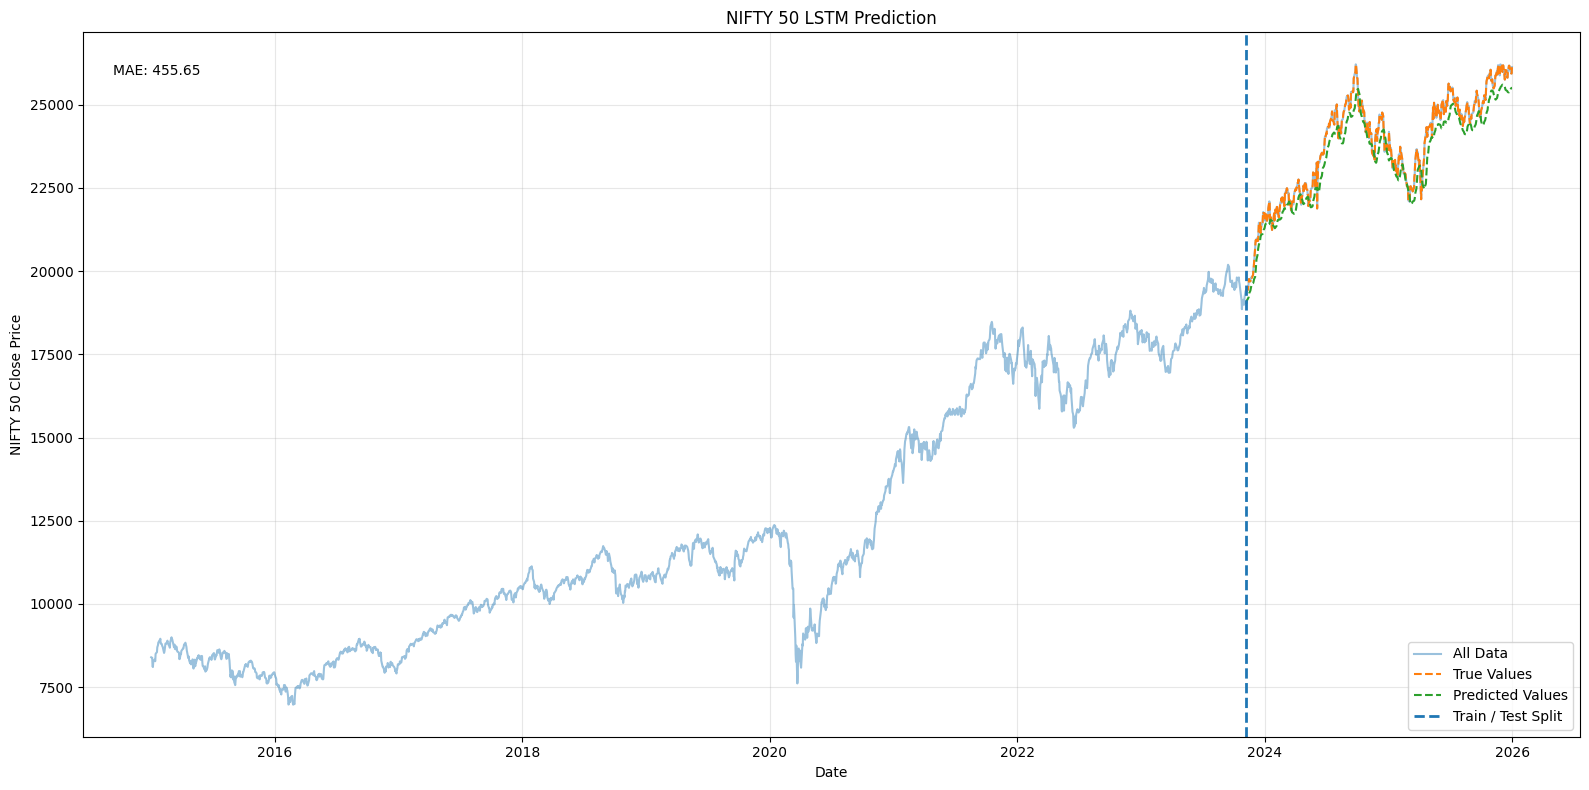

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# ---------- 1. Load CSV ----------
data = pd.read_csv("nifty50.csv", skiprows=3, header=None,
                   names=["Date", "Adj Close", "Close", "High",
                          "Low", "Open", "Volume"])

data["Date"] = pd.to_datetime(data["Date"])
data["Close"] = pd.to_numeric(data["Close"], errors="coerce")
data = data.dropna(subset=["Close"]).sort_values("Date")

dates = data["Date"]
prices = data["Close"].values.reshape(-1, 1)

print("Total records:", len(prices))

# ---------- 2. Normalize ----------
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(prices)

# ---------- 3. Create sequences ----------
sequence_length = 60

X, y = [], []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, 0])
    y.append(scaled_data[i, 0])

X = np.array(X).reshape(-1, sequence_length, 1)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

# ---------- 4. Train / Test Split ----------
train_size = int(len(X) * 0.80)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# ---------- 5. Build and Train LSTM ----------
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(60, 1)),
    Dropout(0.2),
    LSTM(64),
    Dropout(0.2),
    Dense(32),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

model.fit(X_train, y_train, epochs=20,
          batch_size=32, verbose=1)

# ---------- 6. Prediction ----------
prediction = scaler.inverse_transform(
    model.predict(X_test, verbose=0)
).flatten()

actual = prices[sequence_length + train_size:].flatten()
test_dates = dates.iloc[sequence_length + train_size:]

# ---------- 7. Evaluation ----------
mae = mean_absolute_error(actual, prediction)

print("\nMean Absolute Error:", mae)

# ---------- 8. Plot ----------
plt.figure(figsize=(16, 8))

plt.plot(dates, prices.flatten(), label="All Data", alpha=0.45)
plt.plot(test_dates, actual, "--", label="True Values")
plt.plot(test_dates, prediction, "--", label="Predicted Values")

plt.axvline(test_dates.iloc[0], linestyle="--",
            linewidth=2, label="Train / Test Split")

plt.title("NIFTY 50 LSTM Prediction")
plt.xlabel("Date")
plt.ylabel("NIFTY 50 Close Price")

plt.text(0.02, 0.94, f"MAE: {mae:.2f}",
         transform=plt.gca().transAxes)

plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()